# PathSnap-ML — Arun: Reference Routes & GPS Noise Analysis (`.route`)

**Status:** Sections 1–4 contain reference-route validation. The separate `arun_spatial_analysis.py` uses Harshitha's shared loader and trip-local CRS utilities to calculate nearest-reference-route spatial-proximity distances. These are not temporal GPS-to-arc matches or measured GPS noise; no operational search radius is recommended. See `arun_spatial_analysis_report.md` for methodology and results.

**Data used:** `train` (80 trips) and `student_test` (10 trips) only. Original files are only read, never modified. Reserved evaluator data is not touched.

**Raw formats (from the Dataset Exploration PDF, verified in Section 1):**
`.track` = lon, lat, ts · `.nodes` = lon, lat (row index = node_id) · `.arcs` = from_node, to_node (row index = arc_id) · `.route` = one arc_id per line.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


def find_project_root(start_dir=None):
    """Find the workspace root whether Jupyter starts in the root or eda/."""
    start = Path.cwd() if start_dir is None else Path(start_dir)
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "eda" / "route_checks.py").is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not find eda/route_checks.py above the notebook working directory: {start}"
    )


PROJECT_ROOT = find_project_root()
EDA_DIR = PROJECT_ROOT / "eda"
if str(EDA_DIR) not in sys.path:
    sys.path.insert(0, str(EDA_DIR))
import route_checks as rc

DATA_ROOT = rc.resolve_data_root()
FIG_DIR, RES_DIR = EDA_DIR / "figures", PROJECT_ROOT / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

trips = rc.list_trips(DATA_ROOT)
print("project root:", PROJECT_ROOT)
print("dataset root:", DATA_ROOT)
print("trips per partition:", pd.Series([p for p, _ in trips]).value_counts().to_dict())

project root: C:\Users\arunr\Desktop\PathSnap-ML
dataset root: C:\Users\arunr\Downloads\Student folder\Student folder
trips per partition: {'train': 80, 'student_test': 10}


## 1. Inventory and file-structure confirmation

**What this does:** for every trip, confirm all four files exist, then record how many rows each contains. These counts are the base table for every later check.

**Why:** the Dataset PDF says not to assume every trip is identical, and not to assume a GPS row corresponds to a network row.

In [2]:
# 1a. File availability: each trip folder should hold exactly <id>.track/.nodes/.arcs/.route
missing = []
for part, tid in trips:
    present = {f.name for f in (DATA_ROOT / part / tid).iterdir()}
    expected = {f"{tid}.{ext}" for ext in ("track", "nodes", "arcs", "route")}
    if expected - present:
        missing.append((part, tid, sorted(expected - present)))
print("trips with missing files:", missing if missing else "none")

# 1b. Peek at the raw text of one small trip (first 3 lines of each file) so the
#     format is verified by eye, not assumed.
tid = "00000052"
for ext in ("track", "nodes", "arcs", "route"):
    lines = (DATA_ROOT / "student_test" / tid / f"{tid}.{ext}").read_text().splitlines()[:3]
    print(f".{ext:<6}", lines)

trips with missing files: none
.track  ['35.858383\t56.799150\t1.000000', '35.858632\t56.799107\t2.000000', '35.859006\t56.798914\t3.000000']
.nodes  ['35.854084\t56.831850', '35.854755\t56.831169', '35.848602\t56.833824']
.arcs   ['0\t287', '0\t924', '1\t261']
.route  ['1680', '1671', '3559']


In [3]:
# 1c. Load every trip once and build the per-trip inventory + validation table.
#     Keep the loaded objects in a dict so later sections don't re-read from disk.
DATA = {}          # (partition, trip_id) -> dict(track, nodes, arcs, route)
rows = []
for part, tid in trips:
    track, nodes, arcs, route = rc.read_trip_raw(DATA_ROOT, part, tid)
    DATA[(part, tid)] = dict(track=track, nodes=nodes, arcs=arcs, route=route)
    row = dict(partition=part, trip_id=tid,
               n_track=len(track), n_nodes=len(nodes), n_arcs=len(arcs))
    row.update(rc.validate_route(route, arcs, nodes))   # Section 2 checks
    rows.append(row)
inv = pd.DataFrame(rows)
inv.head()

,partition,trip_id,n_track,n_nodes,n_arcs,route_all_int,n_arc_node_oob,n_route,n_out_of_range,n_consecutive_dup,n_unique,n_repeated_ids
0,train,00000001,1315,88809,165790,True,0,525,0,0,525,0
1,train,00000002,7243,7936,16139,True,0,262,0,0,262,0
2,train,00000003,821,9138,18028,True,0,79,0,0,79,0
3,train,00000004,1064,7350,15499,True,0,320,0,0,320,0
4,train,00000005,1045,898,1579,True,0,105,0,0,105,0


## 2. Route structure and arc-ID validity

**What this does:** checks that every `.route` file is a sequence of integers, that each integer is a valid row index of that trip's `.arcs` file (so it really is an `arc_id`), and looks for immediate repeats and arcs visited more than once.

**Why:** the brief says `.route` *appears* to hold arc IDs; this verifies it programmatically before any other analysis depends on it.

In [4]:
print("all route files parse as integers :", bool(inv.route_all_int.all()))
print("total route arc IDs               :", int(inv.n_route.sum()))
print("route IDs NOT present in .arcs    :", int(inv.n_out_of_range.sum()),
      f"(trips affected: {(inv.n_out_of_range > 0).sum()})")
print("arcs pointing to missing node IDs :", int(inv.n_arc_node_oob.sum()))
print("immediate repeated arc IDs        :", int(inv.n_consecutive_dup.sum()))
print("repeated arc ID occurrences       :", int(inv.n_repeated_ids.sum()),
      f"(trips affected: {(inv.n_repeated_ids > 0).sum()})")
print()
print(inv[inv.n_repeated_ids > 0][["partition", "trip_id", "n_route", "n_unique", "n_repeated_ids"]]
      .sort_values("n_repeated_ids", ascending=False).to_string(index=False))

all route files parse as integers : True
total route arc IDs               : 34813
route IDs NOT present in .arcs    : 0 (trips affected: 0)
arcs pointing to missing node IDs : 0
immediate repeated arc IDs        : 0
repeated arc ID occurrences       : 322 (trips affected: 10)

   partition  trip_id  n_route  n_unique  n_repeated_ids
student_test 00000056     1323      1068             255
       train 00000069      467       438              29
       train 00000092     2266      2252              14
       train 00000018      166       157               9
       train 00000095      306       299               7
       train 00000086      671       669               2
       train 00000075      108       106               2
       train 00000084      627       625               2
       train 00000008      173       172               1
       train 00000090      235       234               1


In [5]:
# Repeated arcs: how far apart (in route positions) are successive visits?
# Small gaps -> back-and-forth movement; large gaps -> genuine later revisit.
rep_rows = []
for (part, tid), d in DATA.items():
    g = rc.repeat_gaps(d["route"])
    if len(g):
        rep_rows.append(dict(partition=part, trip_id=tid, n_repeats=len(g),
                             min_gap=g.min(), median_gap=float(np.median(g)),
                             max_gap=g.max(), share_gap_le_3=float((g <= 3).mean())))
rep = pd.DataFrame(rep_rows).sort_values("n_repeats", ascending=False)
print(rep.round(3).to_string(index=False))
rep.to_csv(RES_DIR / "arun_route_repeats.csv", index=False)

   partition  trip_id  n_repeats  min_gap  median_gap  max_gap  share_gap_le_3
student_test 00000056        255       33       225.0     1059             0.0
       train 00000069         29       17        17.0       17             0.0
       train 00000092         14       68        68.0       68             0.0
       train 00000018          9       22        22.0       22             0.0
       train 00000095          7       50        50.0       50             0.0
       train 00000086          2        3         3.0        3             1.0
       train 00000075          2       86        86.0       86             0.0
       train 00000084          2        8         8.0        8             0.0
       train 00000008          1       29        29.0       29             0.0
       train 00000090          1       16        16.0       16             0.0


## 3. Route continuity

**Rule:** for consecutive route arcs *i* and *i+1*, `to_node(arc_i)` must equal `from_node(arc_{i+1})`. A mismatch is a **continuity break**.

**What this does:** counts breaks per trip and, for each break, computes the shortest *directed* path (in hops) between the two nodes in that trip's network. That shows whether a break is a small omission (1–2 missing arcs), a long gap, or unreachable in the directed graph. No distances in metres are used here (that needs the CRS).

In [6]:
break_tables = []
for (part, tid), d in DATA.items():
    b = rc.find_continuity_breaks(d["route"], d["arcs"])
    if len(b):
        # Directed graph of this trip's network, to measure how many arcs are 'missing' at each break.
        G = nx.DiGraph(); G.add_edges_from(zip(d["arcs"].from_node, d["arcs"].to_node))
        hops = []
        for u, v in zip(b.to_node_a, b.from_node_b):
            try:   hops.append(nx.shortest_path_length(G, u, v))
            except nx.NetworkXNoPath: hops.append(np.nan)   # no directed path exists
        b["hops_to_bridge"] = hops
        b.insert(0, "trip_id", tid); b.insert(0, "partition", part)
        b["route_len"] = len(d["route"])
        break_tables.append(b)
breaks = pd.concat(break_tables, ignore_index=True) if break_tables else pd.DataFrame()

n_pairs = int((inv.n_route - 1).sum())
print(f"consecutive arc pairs tested : {n_pairs}")
print(f"continuity breaks            : {len(breaks)}  ({len(breaks)/n_pairs:.4%} of pairs)")
print(f"trips with >= 1 break        : {breaks.trip_id.nunique()} of {len(inv)}")
print("breaks by partition          :", breaks.partition.value_counts().to_dict())
print()
print(breaks.to_string(index=False))
breaks.to_csv(RES_DIR / "arun_route_breaks.csv", index=False)

consecutive arc pairs tested : 34723
continuity breaks            : 14  (0.0403% of pairs)
trips with >= 1 break        : 11 of 90
breaks by partition          : {'train': 13, 'student_test': 1}

   partition  trip_id  route_pos  arc_a  arc_b  to_node_a  from_node_b  hops_to_bridge  route_len
       train 00000002         53   1848  10863       5059         5289            41.0        262
       train 00000019         94  85589  51027        849        23488            17.0        545
       train 00000019        151  55059  55050      25413        25408            12.0        545
       train 00000019        300    953  23709      10107        10862             6.0        545
       train 00000033        164   1003   1002       1283          563             1.0        169
       train 00000041         12   1264    519        349          348             6.0        340
       train 00000042       1212  14661  17989       1762         8726             1.0       1440
       train 0000006

## 4. Route length vs number of GPS observations

**What this does:** compares the number of route arcs with the number of GPS points per trip, and derives the *trip-level average* number of GPS points per route arc.

**Important limitation:** neither `.route` nor `.track` contains any link saying *which GPS point belongs to which arc*. The per-arc count therefore **cannot be read from the files**; it requires an alignment step (Section 5, pending CRS). The figure below is only an average, not a per-arc count.

In [7]:
inv["points_per_arc"] = inv.n_track / inv.n_route
inv["route_ge_track"] = inv.n_route >= inv.n_track
print("trips where n_route >= n_track:", int(inv.route_ge_track.sum()))
print()
print(inv[["n_track", "n_route", "points_per_arc"]].describe().round(2))
print()
print("train vs student_test (mean points_per_arc):")
print(inv.groupby("partition")["points_per_arc"].agg(["count", "mean", "median", "min", "max"]).round(2))

trips where n_route >= n_track: 0

        n_track  n_route  points_per_arc
count     90.00    90.00           90.00
mean    2528.63   386.81            8.14
std     3157.00   359.24            8.98
min      262.00    59.00            1.26
25%      899.25   166.75            3.30
50%     1496.50   272.50            5.25
75%     2816.25   464.25            9.46
max    19313.00  2266.00           56.98

train vs student_test (mean points_per_arc):
              count  mean  median   min    max
partition                                     
student_test     10  7.05    4.63  2.45  14.59
train            80  8.28    5.29  1.26  56.98


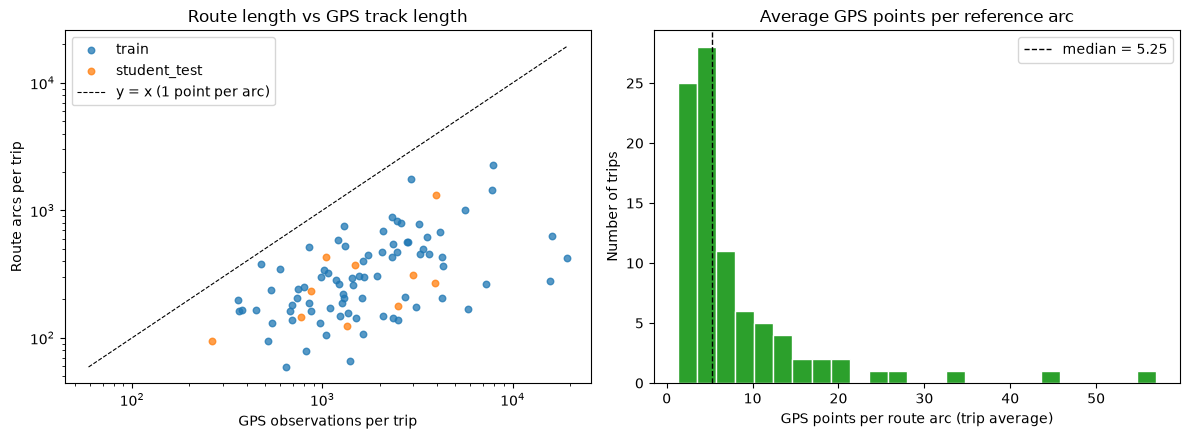

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) route length vs track length, log-log so short and very long trips are both visible
for part, c in (("train", "tab:blue"), ("student_test", "tab:orange")):
    s = inv[inv.partition == part]
    ax[0].scatter(s.n_track, s.n_route, s=22, alpha=0.75, c=c, label=part)
lim = [inv[["n_track", "n_route"]].min().min(), inv[["n_track", "n_route"]].max().max()]
ax[0].plot(lim, lim, "k--", lw=0.8, label="y = x (1 point per arc)")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("GPS observations per trip"); ax[0].set_ylabel("Route arcs per trip")
ax[0].set_title("Route length vs GPS track length"); ax[0].legend()

# (b) distribution of the trip-level average points per arc
ax[1].hist(inv.points_per_arc, bins=25, color="tab:green", edgecolor="white")
ax[1].axvline(inv.points_per_arc.median(), color="k", ls="--", lw=1,
              label=f"median = {inv.points_per_arc.median():.2f}")
ax[1].set_xlabel("GPS points per route arc (trip average)"); ax[1].set_ylabel("Number of trips")
ax[1].set_title("Average GPS points per reference arc"); ax[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "arun_route_vs_track.png", dpi=150)
plt.show()

In [9]:
# Compare generated tables with the existing results before writing anything.
cols = ["partition", "trip_id", "n_track", "n_nodes", "n_arcs", "n_route", "n_unique",
        "n_repeated_ids", "n_consecutive_dup", "n_out_of_range", "n_arc_node_oob",
        "points_per_arc"]
bt = breaks.groupby(["partition", "trip_id"]).size().rename("n_breaks").reset_index() if len(breaks) else None
out = inv[cols].merge(bt, how="left", on=["partition", "trip_id"]) if bt is not None else inv[cols].assign(n_breaks=0)
out["n_breaks"] = out["n_breaks"].fillna(0).astype(int)

candidates = {
    "arun_route_validation.csv": out,
    "arun_route_breaks.csv": breaks,
    "arun_route_repeats.csv": rep,
}
for filename, generated in candidates.items():
    baseline_path = RES_DIR / filename
    if not baseline_path.exists():
        print(f"no existing baseline to compare: {filename}")
        continue
    baseline = pd.read_csv(baseline_path, dtype={"trip_id": str})
    try:
        pd.testing.assert_frame_equal(
            baseline.reset_index(drop=True), generated.reset_index(drop=True),
            check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
        )
    except AssertionError as exc:
        raise RuntimeError(
            f"Generated {filename} differs from the existing result; no result CSVs were overwritten."
        ) from exc
    print(f"existing baseline matches regenerated data: {filename}")

print()
print("Totals from the regenerated dataset:")
print("route arc IDs:", int(inv.n_route.sum()))
print("invalid route arc IDs:", int(inv.n_out_of_range.sum()))
print("arcs with invalid node references:", int(inv.n_arc_node_oob.sum()))
print("continuity breaks:", len(breaks), "across", breaks.trip_id.nunique(), "trips")
print("repeated arc ID occurrences:", int(inv.n_repeated_ids.sum()),
      "across", int((inv.n_repeated_ids > 0).sum()), "trips")

# Baselines matched (or were absent), so write the newly verified outputs.
out.to_csv(RES_DIR / "arun_route_validation.csv", index=False)
breaks.to_csv(RES_DIR / "arun_route_breaks.csv", index=False)
rep.to_csv(RES_DIR / "arun_route_repeats.csv", index=False)
print("saved verified route tables and figures/arun_route_vs_track.png")

existing baseline matches regenerated data: arun_route_validation.csv
existing baseline matches regenerated data: arun_route_breaks.csv
existing baseline matches regenerated data: arun_route_repeats.csv

Totals from the regenerated dataset:
route arc IDs: 34813
invalid route arc IDs: 0
arcs with invalid node references: 0
continuity breaks: 14 across 11 trips
repeated arc ID occurrences: 322 across 10 trips
saved verified route tables and figures/arun_route_vs_track.png


## Spatial follow-up (separate script)

The route files provide arc sequence but no GPS timestamp or point index, so temporal GPS-to-arc alignment and true GPS-noise measurement remain unresolved. The separate spatial analysis reports nearest-reference-route geometry proximity only; its coverage figures are not candidate recall or miss rates.

Run `py -3.10 eda\arun_spatial_analysis.py` from the project root. See `arun_spatial_analysis_report.md` and the appended findings in `data_quality_log.md` for the CRS, results, and limitations.